# Logistische Regression „from scratch“

Begleitnotebook zu **Vorlesung 5: Logistische Regression**.

In diesem Notebook implementieren wir logistische Regression mit **Gradient Descent** selbst – ohne fertige ML-Bibliothek, nur mit NumPy. So sehen wir, was hinter `sklearn.linear_model.LogisticRegression` steckt.

**Aufbau**

| Teil | Inhalt |
|---|---|
| 1 | Logistische Regression mit **einem** Feature: logistische Funktion, Cross Entropy, Gradienten, Gradient Descent, Decision Boundary |
| 2 | **Zwei** Features, Decision Boundary als Gerade, trennbare Daten |
| 3 | Evaluation: Entscheidungsfälle, Accuracy, Precision, Recall, F1 |
| 4 | Größeres Beispiel (Titanic): mehrere Features, Schwellenwert, Feature Importance |
| 5 | Mehrere Klassen: One-vs-all, Confusion Matrix |

**Notation (wie auf den Folien)**

- $n$ = Anzahl der Datenpunkte, Index $i$
- $d$ = Anzahl der Features, Index $j$
- $w_0$ = Achsenabschnitt, $w_1, \dots, w_d$ = Gewichte der Features
- $\sigma(z) = \frac{1}{1 + e^{-z}}$ = logistische Funktion (Sigmoid-Funktion)
- $f(x_i) = \sigma(w_0 + w_1 x_{i1} + \dots + w_d x_{id})$ = vorhergesagte Wahrscheinlichkeit für Klasse 1
- $\hat{y}_i$ = vorhergesagte Klasse für Datenpunkt $i$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)  # reproduzierbare Ergebnisse

---
# Teil 1: Ein Feature

## 1.1 Daten

Wir nutzen den **DMV-Datensatz**: Für 100 Personen sind die Punktzahlen in zwei schriftlichen Führerscheintests (`DMV_Test_1`, `DMV_Test_2`, jeweils 0–100) angegeben und ob die Person insgesamt **bestanden** hat (`Results`: 1 = bestanden, 0 = nicht bestanden).

Das Label ist jetzt **kategorisch** mit zwei Klassen – es handelt sich um **binäre Klassifizierung**.

Zunächst betrachten wir nur ein Feature: **Punktzahl in Test 1 → bestanden?** (wie das Schuhgrößen-Beispiel in der Vorlesung).

In [2]:
df = pd.read_csv("../data/DMV_Written_Tests.csv")
df.head()

,DMV_Test_1,DMV_Test_2,Results
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


Nicht bestanden (0): 40, bestanden (1): 60


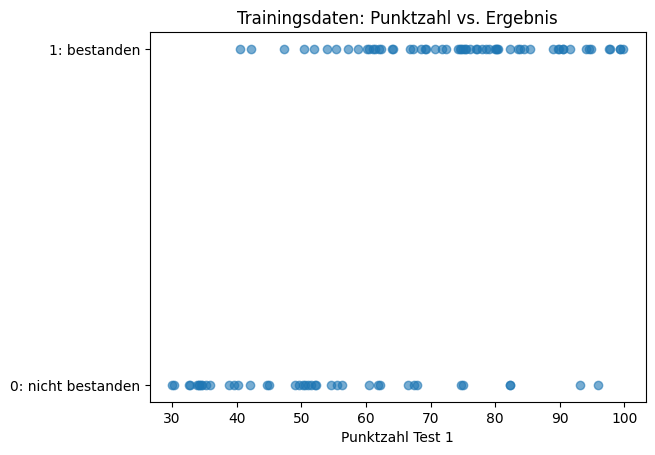

In [3]:
x = df["DMV_Test_1"].values   # Feature
y = df["Results"].values      # Label (0 oder 1)

print(f"Nicht bestanden (0): {np.sum(y == 0)}, bestanden (1): {np.sum(y == 1)}")

plt.scatter(x, y, alpha=0.6)
plt.yticks([0, 1], ["0: nicht bestanden", "1: bestanden"])
plt.xlabel("Punktzahl Test 1")
plt.title("Trainingsdaten: Punktzahl vs. Ergebnis")
plt.show()

Die beiden Klassen überlappen: Wer in Test 1 viele Punkte hat, besteht meistens – aber nicht immer.

## 1.2 Erste Idee: lineare Regression?

Was passiert, wenn wir einfach eine lineare Regression auf die Labels 0 und 1 trainieren?

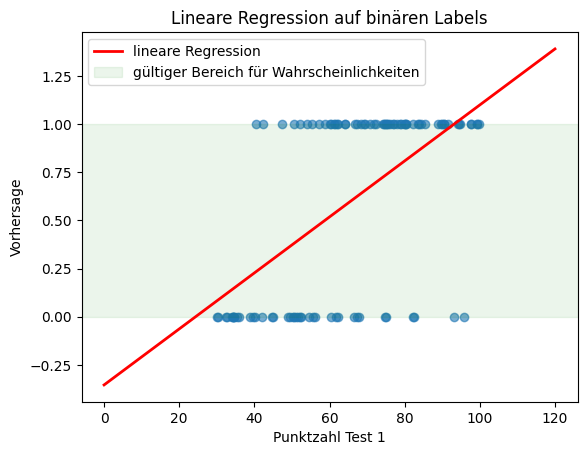

Vorhersage für  10 Punkte: -0.208
Vorhersage für  60 Punkte: 0.518
Vorhersage für 110 Punkte: 1.244


In [4]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression().fit(x.reshape(-1, 1), y)

x_line = np.linspace(0, 120, 200)
plt.scatter(x, y, alpha=0.6)
plt.plot(x_line, lin.predict(x_line.reshape(-1, 1)), color="red", lw=2, label="lineare Regression")
plt.axhspan(0, 1, color="green", alpha=0.08, label="gültiger Bereich für Wahrscheinlichkeiten")
plt.xlabel("Punktzahl Test 1"); plt.ylabel("Vorhersage")
plt.legend(); plt.title("Lineare Regression auf binären Labels")
plt.show()

for punkte in [10, 60, 110]:
    print(f"Vorhersage für {punkte:>3} Punkte: {lin.predict([[punkte]])[0]:.3f}")

Zwei Probleme:

- Ein Wert wie 0.6 ist **keine Klasse**. Wir könnten ihn als **Wahrscheinlichkeit** für Klasse 1 deuten …
- … aber die Gerade verlässt den Bereich $[0, 1]$: Für 10 Punkte kommt ein negativer Wert heraus, für 110 Punkte ein Wert über 1. Das sind **keine Wahrscheinlichkeiten**.

Wir brauchen eine Funktion, die immer zwischen 0 und 1 liegt.

## 1.3 Die logistische Funktion

Die **logistische Funktion** (auch **Sigmoid-Funktion**) bildet jede reelle Zahl auf $(0, 1)$ ab:

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \sigma: \mathbb{R} \to (0, 1)$$

In [5]:
def sigmoid(z):
    # Logistische Funktion: bildet beliebige Zahlen auf (0, 1) ab
    return 1 / (1 + np.exp(-z))

print("σ(-10) =", sigmoid(-10))
print("σ(0)   =", sigmoid(0))
print("σ(10)  =", sigmoid(10))

σ(-10) = 4.5397868702434395e-05
σ(0)   = 0.5
σ(10)  = 0.9999546021312976


Wie in der Vorlesung lässt sich die Kurve verschieben und ihre Steigung verändern. Genau das werden später die Gewichte $w_0$ und $w_1$ tun: In $\sigma(w_0 + w_1 x)$ **verschiebt** $w_0$ die Kurve und $w_1$ bestimmt ihre **Steigung**.

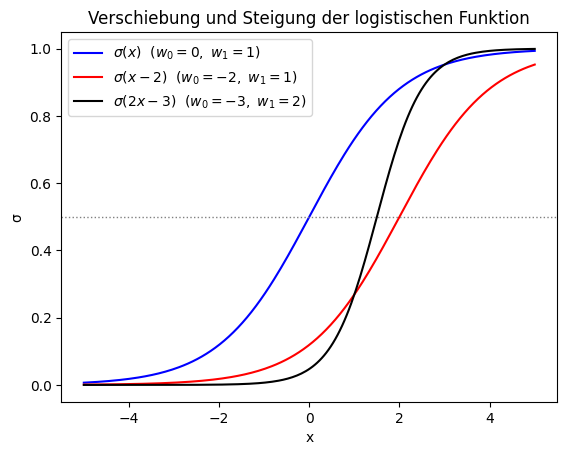

In [6]:
z = np.linspace(-5, 5, 200)
plt.plot(z, sigmoid(z), label=r"$\sigma(x)$  ($w_0=0,\ w_1=1$)", color="blue")
plt.plot(z, sigmoid(z - 2), label=r"$\sigma(x-2)$  ($w_0=-2,\ w_1=1$)", color="red")
plt.plot(z, sigmoid(2 * z - 3), label=r"$\sigma(2x-3)$  ($w_0=-3,\ w_1=2$)", color="black")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xlabel("x"); plt.ylabel("σ")
plt.legend(); plt.title("Verschiebung und Steigung der logistischen Funktion")
plt.show()

Der Mittelpunkt ($\sigma = 0.5$) liegt dort, wo das Argument null ist: bei $x = 2$ (rot) bzw. $x = 1.5$ (schwarz).

## 1.4 Das Modell

Statt einer Geraden nutzt die logistische Regression die logistische Funktion als Vorhersagefunktion:

$$f(x) = \sigma(w_0 + w_1 x_1 + \dots + w_d x_d) = \frac{1}{1 + e^{-(w_0 + w_1 x_1 + \dots + w_d x_d)}}$$

$f(x)$ ist die **Wahrscheinlichkeit, dass $x$ zur Klasse 1 gehört**.

Wir schreiben die Funktion gleich so, dass sie mit beliebig vielen Features funktioniert: Die Datenmatrix $X$ hat $n$ Zeilen (Datenpunkte) und $d$ Spalten (Features), und `X @ w` berechnet $\sum_j w_j x_{ij}$ für alle Datenpunkte gleichzeitig.

Zum Test rechnen wir das Beispiel aus der Vorlesung nach: Schuhgröße 44, Körpergröße 179, Gewichte $w_0 = -30$, $w_1 = 0.2$, $w_2 = 0.13$.

In [7]:
def predict_proba(w0, w, X):
    # Wahrscheinlichkeit für Klasse 1: f(x) = σ(w0 + Σ_j w_j x_j)
    return sigmoid(w0 + X @ w)

X_bsp = np.array([[44, 179]])            # ein Datenpunkt mit zwei Features
w0_bsp, w_bsp = -30, np.array([0.2, 0.13])

z_bsp = w0_bsp + X_bsp @ w_bsp
print(f"w0 + w1·x1 + w2·x2 = {z_bsp[0]:.2f}")
print(f"f(x) = σ({z_bsp[0]:.2f}) = {predict_proba(w0_bsp, w_bsp, X_bsp)[0]:.4f}")

w0 + w1·x1 + w2·x2 = 2.07
f(x) = σ(2.07) = 0.8880


Die Person ist also mit einer Wahrscheinlichkeit von rund 89 % „männlich“.

Für eine konkrete Klasse runden wir die Wahrscheinlichkeit:

$$\hat{y} = \begin{cases} 1 & \text{wenn } f(x) \geq 0.5 \\ 0 & \text{wenn } f(x) < 0.5 \end{cases}$$

In [8]:
def predict_class(w0, w, X, threshold=0.5):
    # Vorhergesagte Klasse: 1, wenn die Wahrscheinlichkeit den Schwellenwert erreicht
    return (predict_proba(w0, w, X) >= threshold).astype(int)

print("Vorhergesagte Klasse:", predict_class(w0_bsp, w_bsp, X_bsp)[0])

Vorhergesagte Klasse: 1


## 1.5 Kostenfunktion: Cross Entropy

Wie gut passen Gewichte zu den Daten? Bei der logistischen Regression nutzen wir die **Cross Entropy**:

$$J(w) = -\frac{1}{n}\sum_{i=1}^{n} \Bigl( y_i \ln f(x_i) + (1 - y_i) \ln\bigl(1 - f(x_i)\bigr) \Bigr)$$

Zwei Hinweise zur Implementierung:

- Wir **teilen durch $n$** (Mittelwert statt Summe). Das ändert die Lage des Minimums nicht, macht aber die Kosten und die passende Lernrate unabhängig von der Anzahl der Datenpunkte.
- `np.log` ist der **natürliche Logarithmus** $\ln$. Den nutzen auch sklearn und die Herleitung des Gradienten. Werte, die mit $\log_2$ berechnet sind, sind um den Faktor $1/\ln 2 \approx 1.44$ größer – an der Lage des Minimums ändert das nichts.

Weil $\ln(0)$ nicht definiert ist, begrenzen wir die Wahrscheinlichkeiten auf $[\varepsilon, 1-\varepsilon]$ mit einem winzigen $\varepsilon$.

In [9]:
def cross_entropy(y, p, eps=1e-12):
    # Mittlere Cross Entropy; p = vorhergesagte Wahrscheinlichkeiten für Klasse 1
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

Für **einen** Datenpunkt fällt einer der beiden Summanden weg: Ist $y_i = 1$, bleibt $-\ln f(x_i)$; ist $y_i = 0$, bleibt $-\ln(1 - f(x_i))$.

Die Beispiele aus der Vorlesung, einmal mit $\ln$ und einmal mit $\log_2$:

In [10]:
beispiele = [(1, 0.3), (1, 0.9), (0, 0.1), (0, 0.7)]   # (y_i, f(x_i))

rows = []
for yi, fi in beispiele:
    ce_ln = cross_entropy(np.array([yi]), np.array([fi]))
    rows.append({"y_i": yi, "f(x_i)": fi, "Kosten (ln)": ce_ln, "Kosten (log2)": ce_ln / np.log(2)})
pd.DataFrame(rows).round(2)

,y_i,f(x_i),Kosten (ln),Kosten (log2)
0,1,0.3,1.20,1.74
1,1,0.9,0.11,0.15
2,0,0.1,0.11,0.15
3,0,0.7,1.20,1.74


**Gute Vorhersagen** ($y_i = 1$ und $f(x_i) = 0.9$) kosten wenig, **schlechte** ($y_i = 1$ und $f(x_i) = 0.3$) viel.

## 1.6 Warum Cross Entropy und nicht MSE?

Es gibt zwei Gründe. Den ersten sehen wir, wenn wir die Kosten eines Datenpunkts mit $y_i = 1$ für alle möglichen Vorhersagen $f(x_i)$ zeichnen:

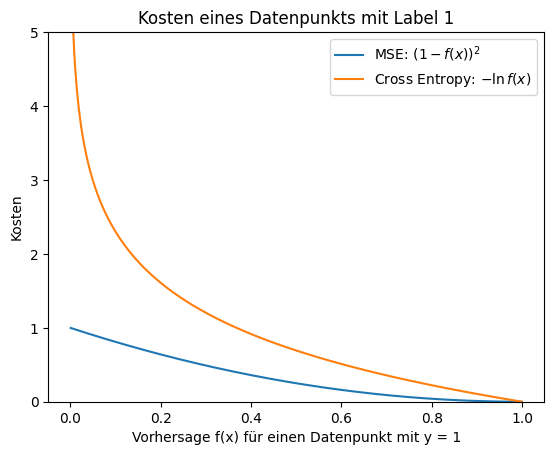

f(x) = 0.1:  MSE = 0.81,  Cross Entropy = 2.30


In [11]:
p = np.linspace(0.001, 0.999, 500)

plt.plot(p, (1 - p) ** 2, label="MSE: $(1 - f(x))^2$")
plt.plot(p, -np.log(p), label="Cross Entropy: $-\\ln f(x)$")
plt.xlabel("Vorhersage f(x) für einen Datenpunkt mit y = 1")
plt.ylabel("Kosten")
plt.ylim(0, 5); plt.legend()
plt.title("Kosten eines Datenpunkts mit Label 1")
plt.show()

print(f"f(x) = 0.1:  MSE = {(1 - 0.1)**2:.2f},  Cross Entropy = {-np.log(0.1):.2f}")

**1. Cross Entropy bestraft Fehler härter.** Liegt das Modell sicher falsch ($f(x) \to 0$ bei $y = 1$), wachsen die Kosten gegen unendlich. Der MSE kann höchstens 1 werden.

Das hat direkte Folgen für das Training. Gradient Descent lernt über den Gradienten, und der hängt bei der logistischen Regression vom Argument $z = w_0 + w_1 x$ ab. Nach der Kettenregel gilt für einen Datenpunkt mit $y = 1$ (mit $\sigma'(z) = \sigma(z)(1 - \sigma(z))$):

- MSE: $\;\frac{\partial}{\partial z}\bigl(1 - \sigma(z)\bigr)^2 = -2\,\bigl(1 - \sigma(z)\bigr)\,\sigma(z)\bigl(1 - \sigma(z)\bigr)$
- Cross Entropy: $\;\frac{\partial}{\partial z}\bigl(-\ln \sigma(z)\bigr) = \sigma(z) - 1$

Beim MSE bleibt der Faktor $\sigma(z)(1 - \sigma(z))$ stehen, bei der Cross Entropy kürzt er sich heraus.

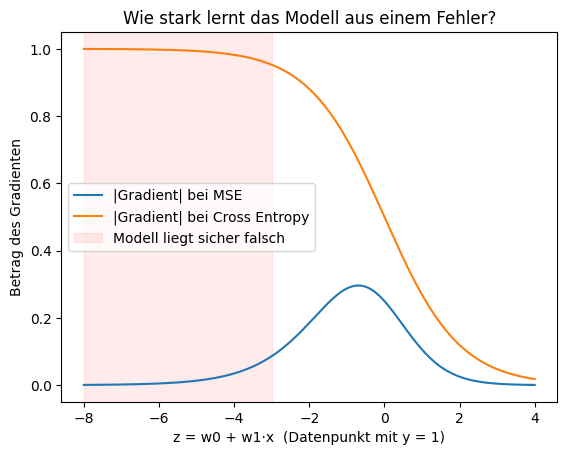

In [12]:
z = np.linspace(-8, 4, 300)
s = sigmoid(z)

plt.plot(z, np.abs(-2 * (1 - s) * s * (1 - s)), label="|Gradient| bei MSE")
plt.plot(z, np.abs(s - 1), label="|Gradient| bei Cross Entropy")
plt.axvspan(-8, -3, color="red", alpha=0.08, label="Modell liegt sicher falsch")
plt.xlabel("z = w0 + w1·x  (Datenpunkt mit y = 1)")
plt.ylabel("Betrag des Gradienten")
plt.legend(); plt.title("Wie stark lernt das Modell aus einem Fehler?")
plt.show()

Genau dort, wo das Modell **sicher falsch** liegt (links), wird der MSE-Gradient fast null – das Modell lernt aus seinen größten Fehlern kaum etwas. Bei der Cross Entropy ist der Gradient dort am größten.

**2. Die Cross Entropy ist konvex**: Es gibt nur ein Minimum, und Gradient Descent findet es bei geeigneter Lernrate. Mit dem MSE ist die Kostenfunktion der logistischen Regression nicht konvex.

## 1.7 Gradienten

Für Gradient Descent brauchen wir die partiellen Ableitungen der Cross Entropy. Weil sich $\sigma'(z)$ herauskürzt, ist das Ergebnis erstaunlich einfach:

$$\frac{\partial J}{\partial w_j} = \frac{1}{n}\sum_{i=1}^{n} \bigl(f(x_i) - y_i\bigr)\, x_{ij} \qquad \text{für } j = 0, \dots, d, \text{ mit } x_{i0} = 1$$

Für $w_0$ ist $x_{i0} = 1$, der Gradient ist also einfach der mittlere Fehler. Mit Matrixschreibweise berechnet `X.T @ error` die Summen $\sum_i x_{ij}\,(f(x_i) - y_i)$ für alle Features auf einmal.

> **Vergleich mit Kapitel 4:** Die Formel sieht fast genauso aus wie bei der linearen Regression. Der einzige Unterschied steckt in $f(x_i)$ – dort eine Gerade, hier die logistische Funktion.

In [13]:
def gradients(w0, w, X, y):
    error = predict_proba(w0, w, X) - y     # f(x_i) - y_i für alle Datenpunkte
    grad_w0 = np.mean(error)                 # x_i0 = 1
    grad_w = X.T @ error / len(y)            # für alle w_j mit j = 1, ..., d
    return grad_w0, grad_w

Ob die Formel stimmt, können wir **numerisch prüfen**: Eine Ableitung ist die Steigung, und die lässt sich näherungsweise als Differenzenquotient berechnen,

$$\frac{\partial J}{\partial w_j} \approx \frac{J(w_j + h) - J(w_j - h)}{2h} \qquad \text{für ein kleines } h.$$

In [14]:
X1 = x.reshape(-1, 1)          # 1 Feature als Matrix mit einer Spalte
w0_test, w_test = -3.0, np.array([0.05])
h = 1e-6

cost = lambda w0, w: cross_entropy(y, predict_proba(w0, w, X1))
num_w0 = (cost(w0_test + h, w_test) - cost(w0_test - h, w_test)) / (2 * h)
num_w1 = (cost(w0_test, w_test + h) - cost(w0_test, w_test - h)) / (2 * h)

g0, g = gradients(w0_test, w_test, X1, y)
print(f"∂J/∂w0:  Formel = {g0:.6f},  numerisch = {num_w0:.6f}")
print(f"∂J/∂w1:  Formel = {g[0]:.6f},  numerisch = {num_w1:.6f}")

∂J/∂w0:  Formel = -0.041044,  numerisch = -0.041044
∂J/∂w1:  Formel = -4.091128,  numerisch = -4.091128


Beide Werte stimmen überein.

> **Kann man das Minimum nicht direkt berechnen?** Bei der linearen Regression setzt man den Gradienten gleich null und löst nach den Gewichten auf (Normalgleichung). Hier stecken die Gewichte im Exponenten von $e$ innerhalb von $f(x_i)$. Die Gleichungen $\sum_i (f(x_i) - y_i)\,x_{ij} = 0$ sind nichtlinear, und es gibt keine allgemeine Lösungsformel. Deshalb suchen wir das Minimum iterativ.

## 1.8 Gradient Descent

Der Algorithmus ist derselbe wie bei der linearen Regression:

- Starte mit zufälligen Gewichten.
- Berechne in jeder Iteration alle Gradienten **mit den alten Gewichten** und aktualisiere dann alle Gewichte gleichzeitig:
  $w_j \leftarrow w_j - \alpha \frac{\partial J}{\partial w_j}$
- Höre auf, wenn der Gradient (fast) null ist.

Diesmal schreiben wir die Klasse gleich für beliebig viele Features.

In [15]:
class LogisticRegressionGD:
    # Logistische Regression (binär) mit beliebig vielen Features, trainiert mit Gradient Descent

    def __init__(self, learning_rate=0.1, max_iterations=20000, tolerance=1e-6):
        self.learning_rate = learning_rate
        self.max_iterations = max_iterations
        self.tolerance = tolerance

    def predict_proba(self, X):
        return predict_proba(self.w0, self.w, X)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def fit(self, X, y):
        n, d = X.shape

        # 1. Zufällige Startwerte für w0 und w1, ..., wd
        self.w0 = np.random.randn() * 0.01
        self.w = np.random.randn(d) * 0.01
        self.cost_history = []

        for iteration in range(self.max_iterations):
            self.cost_history.append(cross_entropy(y, self.predict_proba(X)))

            # 2. Alle Gradienten mit den alten Gewichten berechnen ...
            grad_w0, grad_w = gradients(self.w0, self.w, X, y)

            # 3. Abbruch, wenn der Gradient fast null ist (Minimum erreicht)
            if np.sqrt(grad_w0 ** 2 + np.sum(grad_w ** 2)) < self.tolerance:
                break

            # 4. ... und dann alle Gewichte gleichzeitig aktualisieren
            self.w0 -= self.learning_rate * grad_w0
            self.w -= self.learning_rate * grad_w

        self.n_iterations = iteration + 1
        return self

## 1.9 Training

Wie in Kapitel 4 gilt: **erst splitten, dann standardisieren** – mit Mittelwert und Standardabweichung der Trainingsdaten. Mit `stratify=y` sorgen wir dafür, dass beide Klassen in Trainings- und Testdaten im gleichen Verhältnis vorkommen.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X1, y, test_size=0.2, random_state=42, stratify=y)

mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

model = LogisticRegressionGD(learning_rate=0.5).fit(X_train_s, y_train)

print(f"Trainingsdaten: {len(y_train)} Punkte, Testdaten: {len(y_test)} Punkte")
print(f"Konvergiert nach {model.n_iterations} Iterationen")
print(f"w0 = {model.w0:.4f}, w1 = {model.w[0]:.4f}")

Trainingsdaten: 80 Punkte, Testdaten: 20 Punkte
Konvergiert nach 225 Iterationen
w0 = 0.5780, w1 = 1.4753


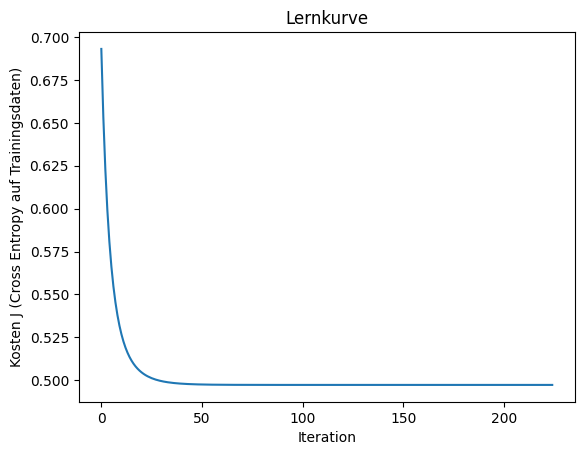

In [17]:
plt.plot(model.cost_history)
plt.xlabel("Iteration")
plt.ylabel("Kosten J (Cross Entropy auf Trainingsdaten)")
plt.title("Lernkurve")
plt.show()

## 1.10 Decision Boundary

Die gelernte Kurve ordnet jedem Punktestand eine Wahrscheinlichkeit zu. Die **Decision Boundary** $x_G$ ist die Stelle mit $f(x_G) = 0.5$. Wegen $\sigma(0) = 0.5$ gilt dort

$$w_0 + w_1 x_G = 0 \quad\Rightarrow\quad x_G = -\frac{w_0}{w_1}.$$

Das Modell hat auf standardisierten Daten gelernt, also rechnen wir $x_G$ wieder in Punkte um: $x_G^{\text{Punkte}} = \mu + \sigma_x \cdot x_G$ (hier ist $\sigma_x$ die Standardabweichung des Features, nicht die logistische Funktion).

Decision Boundary: 57.8 Punkte in Test 1


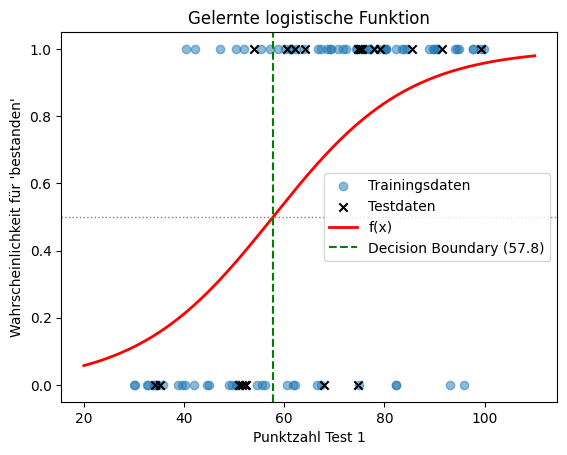

In [18]:
x_G = -model.w0 / model.w[0]
x_G_punkte = mu[0] + sigma[0] * x_G
print(f"Decision Boundary: {x_G_punkte:.1f} Punkte in Test 1")

x_line = np.linspace(20, 110, 300).reshape(-1, 1)
plt.scatter(X_train[:, 0], y_train, alpha=0.5, label="Trainingsdaten")
plt.scatter(X_test[:, 0], y_test, marker="x", color="black", label="Testdaten")
plt.plot(x_line, model.predict_proba((x_line - mu) / sigma), color="red", lw=2, label="f(x)")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.axvline(x_G_punkte, color="green", ls="--", label=f"Decision Boundary ({x_G_punkte:.1f})")
plt.xlabel("Punktzahl Test 1"); plt.ylabel("Wahrscheinlichkeit für 'bestanden'")
plt.legend(loc="center right"); plt.title("Gelernte logistische Funktion")
plt.show()

Rechts der Decision Boundary sagt das Modell „bestanden“ vorher, links „nicht bestanden“.

> **Achtung:** Das gilt nur, weil $w_1 > 0$ ist (mehr Punkte → höhere Wahrscheinlichkeit). Bei einem negativen Gewicht wäre es umgekehrt.

Wie oft liegt das Modell auf den Testdaten richtig?

In [19]:
acc_1 = np.mean(model.predict(X_test_s) == y_test)
print(f"Anteil korrekter Vorhersagen auf den Testdaten: {acc_1:.2f}")

Anteil korrekter Vorhersagen auf den Testdaten: 0.85


Diesen Anteil nennt man **Accuracy**. In Teil 3 schauen wir uns Evaluationsmetriken genauer an.

## 1.11 Vergleich mit sklearn

In der Praxis nutzt man `sklearn.linear_model.LogisticRegression`. Zwei Unterschiede zu unserer Implementierung:

- sklearn nutzt kein reines Gradient Descent, sondern standardmäßig das Verfahren `lbfgs`, das schneller konvergiert. Das Minimum ist dasselbe.
- sklearn **regularisiert** standardmäßig: Der Parameter `C=1.0` bestraft große Gewichte und zieht sie Richtung null. Mit einem sehr großen `C` schalten wir das praktisch ab und lösen genau unser Problem.

Mit `tol=1e-8` rechnet sklearn außerdem so genau wie unser Modell. Mit dem Standardwert `tol=1e-4` bricht `lbfgs` etwas früher ab, und die Gewichte weichen ab der dritten Nachkommastelle ab.

In [20]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(C=1e6, tol=1e-8).fit(X_train_s, y_train)   # praktisch ohne Regularisierung
sk_default = LogisticRegression().fit(X_train_s, y_train)                # Standard: C = 1.0

print(f"Unser Modell:             w0 = {model.w0:.4f}, w1 = {model.w[0]:.4f}")
print(f"sklearn (C = 1e6):        w0 = {sk_model.intercept_[0]:.4f}, w1 = {sk_model.coef_[0, 0]:.4f}")
print(f"sklearn (Standard C = 1): w0 = {sk_default.intercept_[0]:.4f}, w1 = {sk_default.coef_[0, 0]:.4f}")

Unser Modell:             w0 = 0.5780, w1 = 1.4753
sklearn (C = 1e6):        w0 = 0.5780, w1 = 1.4753
sklearn (Standard C = 1): w0 = 0.5503, w1 = 1.3318


Ohne Regularisierung finden beide Verfahren dieselben Gewichte. Mit der Standardeinstellung ist das Gewicht etwas kleiner – das ist gewollt und schützt vor Overfitting, sollte man aber kennen, wenn man Gewichte interpretiert.

---
# Teil 2: Zwei Features

## 2.1 Training mit beiden Tests

Jetzt nutzen wir beide Testergebnisse als Features. Unsere Klasse funktioniert ohne Änderung, $X$ hat einfach zwei Spalten.

In [21]:
features = ["DMV_Test_1", "DMV_Test_2"]
X2 = df[features].values

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

mu2, sigma2 = X2_train.mean(axis=0), X2_train.std(axis=0)    # pro Feature
X2_train_s = (X2_train - mu2) / sigma2
X2_test_s = (X2_test - mu2) / sigma2

model2 = LogisticRegressionGD(learning_rate=0.5).fit(X2_train_s, y2_train)
sk_model2 = LogisticRegression(C=1e6, tol=1e-8).fit(X2_train_s, y2_train)

print(f"Konvergiert nach {model2.n_iterations} Iterationen")
print(f"Unser Modell: w0 = {model2.w0:.4f}, w = {np.round(model2.w, 4)}")
print(f"sklearn:      w0 = {sk_model2.intercept_[0]:.4f}, w = {np.round(sk_model2.coef_[0], 4)}")

acc_2 = np.mean(model2.predict(X2_test_s) == y2_test)
print(f"\nAccuracy auf Testdaten mit 1 Feature:  {acc_1:.2f}")
print(f"Accuracy auf Testdaten mit 2 Features: {acc_2:.2f}")

Konvergiert nach 2677 Iterationen
Unser Modell: w0 = 1.5858, w = [3.7728 3.4554]
sklearn:      w0 = 1.5858, w = [3.7729 3.4555]

Accuracy auf Testdaten mit 1 Feature:  0.85
Accuracy auf Testdaten mit 2 Features: 0.95


## 2.2 Decision Boundary als Gerade

Mit zwei Features ist die Decision Boundary eine **Gerade**: alle Punkte mit $f(x) = 0.5$, also

$$w_0 + w_1 x_1 + w_2 x_2 = 0 \quad\Rightarrow\quad x_2 = -\frac{w_0 + w_1 x_1}{w_2}.$$

Wir zeichnen sie zusammen mit der vorhergesagten Wahrscheinlichkeit als Farbverlauf. Damit wir in Punkten zeichnen können, rechnen wir jeden Gitterpunkt erst in standardisierte Werte um.

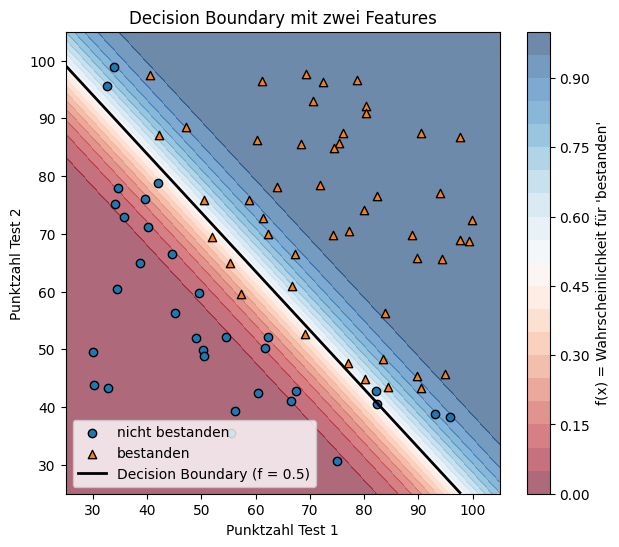

In [22]:
g1, g2 = np.meshgrid(np.linspace(25, 105, 200), np.linspace(25, 105, 200))
grid = np.column_stack([g1.ravel(), g2.ravel()])
proba = model2.predict_proba((grid - mu2) / sigma2).reshape(g1.shape)

plt.figure(figsize=(7, 6))
cf = plt.contourf(g1, g2, proba, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(cf, label="f(x) = Wahrscheinlichkeit für 'bestanden'")
plt.contour(g1, g2, proba, levels=[0.5], colors="black", linewidths=2)

for klasse, marker, name in [(0, "o", "nicht bestanden"), (1, "^", "bestanden")]:
    m = y2_train == klasse
    plt.scatter(X2_train[m, 0], X2_train[m, 1], marker=marker, edgecolor="black", label=name)

plt.plot([], [], color="black", lw=2, label="Decision Boundary (f = 0.5)")
plt.xlabel("Punktzahl Test 1"); plt.ylabel("Punktzahl Test 2")
plt.legend(loc="lower left"); plt.title("Decision Boundary mit zwei Features")
plt.show()

Die Gerade trennt die Klassen nicht perfekt, aber gut. Mit drei Features wäre die Decision Boundary eine Ebene, mit mehr Features eine Hyperebene.

Die logistische Regression kann grundsätzlich **nur lineare** Decision Boundaries lernen. Ob das reicht, hängt vom Problem ab.

## 2.3 Sonderfall: perfekt trennbare Daten

Was passiert, wenn eine Gerade die Klassen **perfekt** trennen kann? Kleinstes Beispiel: zwei Datenpunkte $(x, y) = (0, 0)$ und $(1, 1)$.

Setzt man den Gradienten nach $w_1$ gleich null, bleibt $f(1) - 1 = 0$, also $f(1) = 1$. Die logistische Funktion erreicht 1 aber nie. Es gibt also **kein Minimum**: Je steiler die Kurve, desto kleiner die Kosten.

In [23]:
X_sep = np.array([[0.0], [1.0]])
y_sep = np.array([0, 1])

print(f"{'Iterationen':>12} {'w0':>8} {'w1':>8} {'Kosten J':>10}")
for iterations in [100, 1000, 10000, 100000]:
    np.random.seed(0)
    m = LogisticRegressionGD(learning_rate=1.0, max_iterations=iterations, tolerance=0).fit(X_sep, y_sep)
    print(f"{iterations:>12} {m.w0:>8.2f} {m.w[0]:>8.2f} {m.cost_history[-1]:>10.6f}")

 Iterationen       w0       w1   Kosten J
         100    -2.71     5.85   0.053866
        1000    -5.09    10.60   0.005094


       10000    -7.42    15.24   0.000501


      100000    -9.72    19.85   0.000050


Die Kosten sinken immer weiter Richtung null, und die Gewichte wachsen unbegrenzt – Gradient Descent konvergiert nie. Das ist einer der Gründe, warum sklearn standardmäßig regularisiert: Die Strafe für große Gewichte sorgt dafür, dass wieder ein Minimum existiert.

---
# Teil 3: Evaluation

## 3.1 Entscheidungsfälle

Für jeden Testdatenpunkt vergleichen wir die vorhergesagte Klasse mit dem Label:

| Vorhersage | Label | Bezeichnung |
|---|---|---|
| 1 | 1 | true positive (tp) |
| 1 | 0 | false positive (fp) |
| 0 | 1 | false negative (fn) |
| 0 | 0 | true negative (tn) |

Zum Testen nutzen wir das Beispiel mit 8 Datenpunkten aus der Vorlesung.

In [24]:
def decision_cases(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    tn = np.sum((y_pred == 0) & (y_true == 0))
    return tp, fp, fn, tn

y_pred_bsp = np.array([1, 1, 0, 1, 1, 0, 0, 0])   # Vorhersage
y_true_bsp = np.array([1, 0, 1, 0, 1, 1, 1, 0])   # Label

tp, fp, fn, tn = decision_cases(y_true_bsp, y_pred_bsp)
print(f"tp = {tp}, fp = {fp}, fn = {fn}, tn = {tn}")

tp = 2, fp = 2, fn = 3, tn = 1


## 3.2 Accuracy, Precision, Recall, F1

$$\text{accuracy} = \frac{tp + tn}{\text{alle}} \qquad
\text{precision} = \frac{tp}{tp + fp} \qquad
\text{recall} = \frac{tp}{tp + fn} \qquad
F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

Sagt ein Modell nie Klasse 1 vorher, ist $tp + fp = 0$ und die Precision nicht definiert. Wie sklearn setzen wir sie dann auf 0.

In [25]:
def accuracy(y_true, y_pred):
    tp, fp, fn, tn = decision_cases(y_true, y_pred)
    return (tp + tn) / len(y_true)

def precision(y_true, y_pred):
    tp, fp, fn, tn = decision_cases(y_true, y_pred)
    return tp / (tp + fp) if tp + fp > 0 else 0.0

def recall(y_true, y_pred):
    tp, fp, fn, tn = decision_cases(y_true, y_pred)
    return tp / (tp + fn) if tp + fn > 0 else 0.0

def f1(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return 2 * p * r / (p + r) if p + r > 0 else 0.0

def report(y_true, y_pred):
    print(f"Accuracy  = {accuracy(y_true, y_pred):.3f}")
    print(f"Precision = {precision(y_true, y_pred):.3f}")
    print(f"Recall    = {recall(y_true, y_pred):.3f}")
    print(f"F1 Score  = {f1(y_true, y_pred):.3f}")

report(y_true_bsp, y_pred_bsp)

Accuracy  = 0.375
Precision = 0.500
Recall    = 0.400
F1 Score  = 0.444


Das sind genau die Werte aus der Vorlesung. Zur Kontrolle mit sklearn:

In [26]:
from sklearn import metrics

print(f"Accuracy  = {metrics.accuracy_score(y_true_bsp, y_pred_bsp):.3f}")
print(f"Precision = {metrics.precision_score(y_true_bsp, y_pred_bsp):.3f}")
print(f"Recall    = {metrics.recall_score(y_true_bsp, y_pred_bsp):.3f}")
print(f"F1 Score  = {metrics.f1_score(y_true_bsp, y_pred_bsp):.3f}")

Accuracy  = 0.375
Precision = 0.500
Recall    = 0.400
F1 Score  = 0.444


Und für unser DMV-Modell mit zwei Features auf den Testdaten:

In [27]:
report(y2_test, model2.predict(X2_test_s))

Accuracy  = 0.950
Precision = 1.000
Recall    = 0.917
F1 Score  = 0.957


> Bei nur 20 Testdatenpunkten ändert jede einzelne Fehlklassifikation die Metriken um mehrere Prozentpunkte. Solche Werte sind daher mit Vorsicht zu genießen.

## 3.3 Die Accuracy-Falle

Das Betrugsbeispiel aus der Vorlesung: Von 100 Transaktionen ist eine Betrug. Ein „Modell“, das **immer „kein Betrug“** vorhersagt:

In [28]:
y_betrug = np.array([1] + [0] * 99)        # 1 Betrug, 99 normale Transaktionen
y_naiv = np.zeros(100, dtype=int)          # sagt immer "kein Betrug" vorher

report(y_betrug, y_naiv)

Accuracy  = 0.990
Precision = 0.000
Recall    = 0.000
F1 Score  = 0.000


99 % Accuracy – und trotzdem erkennt das Modell keinen einzigen Betrug. Recall und F1 Score zeigen das sofort. Bei unbalancierten Klassen sollte man Accuracy daher nie allein betrachten.